## 1. Assignment -5-
**Behavioral Mining and Sequence Modeling in ML Systems (MovieLens 100K)**

## 2. Context & Scenario
You are supporting a streaming platform analytics team focused on improving user engagement and session continuity. Your objective is to build a reproducible, deployment-oriented workflow that supports (i) **co-consumption insights** for recommendation/bundling and (ii) **next-step behavior prediction** for ranking. Your notebook must explicitly address leakage prevention, operational monitoring, and inference-time constraints.

## 3. Dataset
Use **MovieLens 100K (GroupLens)**:
- Dataset page: https://grouplens.org/datasets/movielens/100k/
- Direct download: https://files.grouplens.org/datasets/movielens/ml-100k.zip
- License: GroupLens usage terms for research/education (cite source in notebook)

Key files:
- `u.data`: `(user_id, movie_id, rating, timestamp)` interaction log (100,000 events)
- `u.item`: movie metadata including release info and binary genre indicators (19 genres)

Treat `timestamp` as event time. Ensure any train/validation/test strategy preserves temporal order for sequence prediction.

## 4. Machine Learning Tasks
- **Data ingestion and validation:** Load `u.data` and `u.item`; verify schema, dtypes, missingness, duplicate rates, and key uniqueness assumptions.
- **Exploratory analysis:** Provide at least **two plots** (at least one using **matplotlib**) and concise interpretations relevant to recommendation and ranking risk.
- **Association mining (from scratch):** Build transaction baskets (for example user-week or user-session), compute **support**, **confidence**, and **lift** with pandas/numpy only, and identify misleading high-confidence low-lift rules.
- **Sequence modeling:** Construct ordered per-user sequences and build a **next-step prediction** target (for example next genre) using a **time-based split** to reduce leakage.
- **Pipeline and preprocessing:** Use `Pipeline` for model training; include `StandardScaler` when appropriate.
- **Classification modeling:** Train a baseline classifier for next-step prediction, report core metrics (for example confusion matrix + classification report), and interpret major failure modes.
- **Threshold/decision analysis:** Evaluate at least two operating points or decision rules aligned to an explicit product objective.
- **ML systems emphasis (written answers):** Provide a brief plan for reproducibility artifacts (seeds, data/versioning, split metadata), monitoring signals (drift/performance), and inference cost implications.

## 5. Deliverables
- Executed Jupyter notebook with code, plots, and brief Markdown interpretations.
- Short written answers embedded in Markdown cells.
- Optional appendix table: experiment log with configuration, split window, and metrics.


## Grading Rubric (100 points)
- **Code correctness & execution — 30 pts** (notebook runs end-to-end; correct pandas/numpy implementation of support/confidence/lift; model training and evaluation execute without leakage).
- **Data validation & EDA quality — 15 pts** (meaningful validation checks; at least two relevant plots with clear labels; interpretations tied to downstream recommendation/ranking risk).
- **Preprocessing & leakage control — 15 pts** (proper temporal split for sequence prediction; `Pipeline` usage is clear; transformations are fit on training data only).
- **Association mining quality — 15 pts** (correct metrics, defensible thresholds, and explicit diagnosis of popularity bias / misleading rules).
- **Sequence model quality — 10 pts** (coherent sequence construction, appropriate target definition, and sound evaluation).
- **Diagnostics & decision analysis — 10 pts** (rule diagnostic + predictive diagnostic; operating threshold/decision tradeoff is justified).
- **ML systems thinking & reproducibility — 5 pts** (clear reproducibility artifacts, monitoring/drift plan, and inference cost considerations).
- **Limitations & next steps — embedded (0–5 pts)** (credible limitations and concrete follow-up experiments assessed within categories above).


_____________________________________________________________________________________________________________________________________________________________________________________

## Data and Reproducibility
Dataset: MovieLens 100K from GroupLens. The notebook downloads the ml-100k.zip archive and uses the u.data and u.item files. The timestamp column is defined as an event time. The MovieLens user/movie IDs are used as identifiers, and the u.item genre columns provide movie metadata. The workflow uses a fixed seed, explicit column names, deterministic sorting, and records dataset dimensions and configuration values.

In [19]:
import os
os.environ["OMP_NUM_THREADS"] = "1"

import io
import zipfile
import urllib.request
import time
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    balanced_accuracy_score
)

SEED = 42
np.random.seed(SEED)

DATA_URL = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
TEST_FRACTION = 0.20
MIN_SUPPORT = 0.02

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python: 3.13.9
Platform: Windows-11-10.0.26200-SP0
NumPy: 2.5.3
Pandas: 2.3.3


## Reproducibility Artifacts

The run must include the dataset URL, its size, the seed, split rules, association thresholds, model's configuration, library versions and the exact notebook/code version. The future production run should also contain a checksum of the downloaded archive and data snapshot's identifier.

In [20]:
with urllib.request.urlopen(DATA_URL) as response:
    archive_bytes = response.read()

archive_sha256 = __import__("hashlib").sha256(archive_bytes).hexdigest()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as z:
    data = pd.read_csv(
        z.open("ml-100k/u.data"),
        sep="\t",
        names=["user_id", "movie_id", "rating", "timestamp"]
    )
    item_cols = ["movie_id", "title", "release_date", "video_release_date", "imdb_url",
                 "unknown", "Action", "Adventure", "Animation", "Children's", "Comedy",
                 "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir", "Horror",
                 "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]
    items = pd.read_csv(z.open("ml-100k/u.item"), sep="|", encoding="latin-1",
                        names=item_cols, header=None)

print("Ratings shape:", data.shape)
print("Items shape:", items.shape)
print("SHA-256:", archive_sha256)

Ratings shape: (100000, 4)
Items shape: (1682, 24)
SHA-256: 50d2a982c66986937beb9ffb3aa76efe955bf3d5c6b761f4e3a7cd717c6a3229


## Data Validation

The expected ratings table contains 100,000 interaction events with four fields. The item table has 1682 movies and 19 binary genre indicators. The data has been validated for data types, missing values, duplicates, keys, rating range, and timestamp conversion.

In [21]:
print(data.info())
print("\nMissing values:")
print(data.isna().sum())
print("\nDuplicate rating rows:", data.duplicated().sum())
print("Unique users:", data["user_id"].nunique())
print("Unique movies in ratings:", data["movie_id"].nunique())
print("Unique movie IDs in metadata:", items["movie_id"].nunique())
print("Rating range:", data["rating"].min(), "to", data["rating"].max())

assert data.shape[0] == 100000
assert data["rating"].between(1, 5).all()
assert data["user_id"].notna().all()
assert data["movie_id"].notna().all()
assert items["movie_id"].is_unique

data["event_time"] = pd.to_datetime(data["timestamp"], unit="s", utc=True)
print("\nDate range:", data["event_time"].min(), "to", data["event_time"].max())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    100000 non-null  int64
 1   movie_id   100000 non-null  int64
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int64(4)
memory usage: 3.1 MB
None

Missing values:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Duplicate rating rows: 0
Unique users: 943
Unique movies in ratings: 1682
Unique movie IDs in metadata: 1682
Rating range: 1 to 5

Date range: 1997-09-20 03:05:10+00:00 to 1998-04-22 23:10:38+00:00


### Validation interpretation
The interaction table is event-level rather than a transaction basket. Multiple ratings from a user are legitimate observations, so a duplicate check is useful for detecting exact duplicate rows but should not assume that repeated users or movies are duplicates. The timestamp is converted once and then used for chronological operations.

## Exploratory Analysis

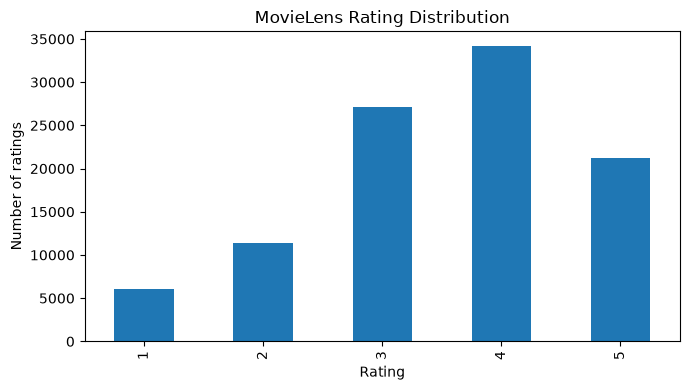

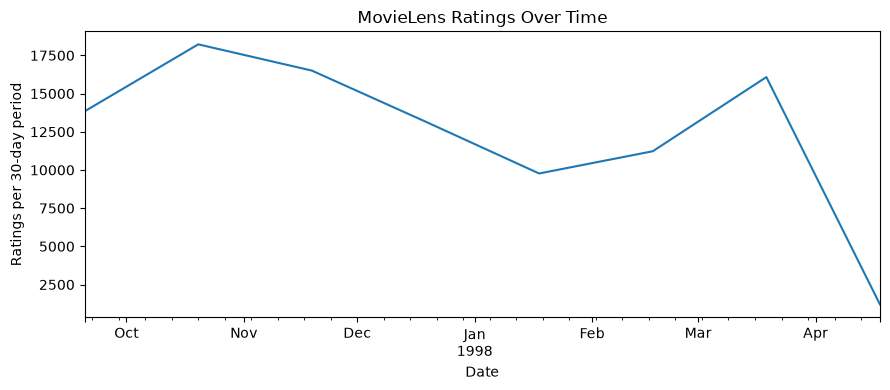

In [22]:
plt.figure(figsize=(7, 4))
data["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("MovieLens Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of ratings")
plt.tight_layout()
plt.show()

# Plot 2: ratings over time
daily = data.set_index("event_time").resample("30D").size()
plt.figure(figsize=(9, 4))
daily.plot()
plt.title("MovieLens Ratings Over Time")
plt.xlabel("Date")
plt.ylabel("Ratings per 30-day period")
plt.tight_layout()
plt.show()

### EDA Interpretation

The rating distribution represents the amount of positive and negative feedback available for the classifier. In this case, a pronounced concentration around certain rating values may indicate that accuracy alone may be misleading due to potential class imbalance. The time plot is important in terms of leakage: interactions are not exchangeable in time, and therefore using future events to create training features would make the evaluation unrealistically optimistic.

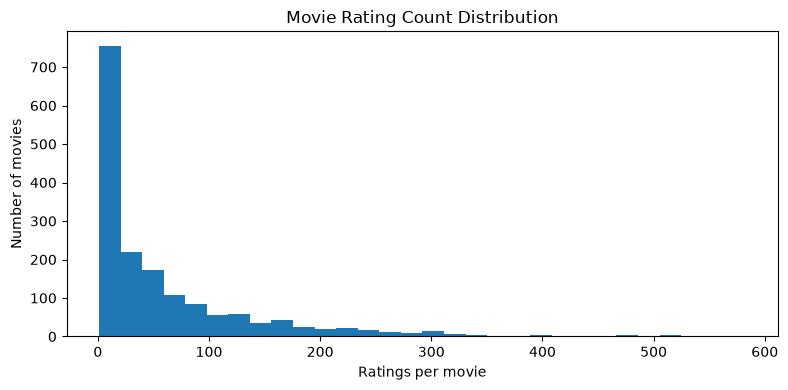

count    1682.000000
mean       59.453032
std        80.383846
min         1.000000
25%         6.000000
50%        27.000000
75%        80.000000
max       583.000000
Name: count, dtype: float64


In [23]:
movie_counts = data["movie_id"].value_counts()
plt.figure(figsize=(8, 4))
plt.hist(movie_counts.values, bins=30)
plt.title("Movie Rating Count Distribution")
plt.xlabel("Ratings per movie")
plt.ylabel("Number of movies")
plt.tight_layout()
plt.show()

print(movie_counts.describe())

## Association Mining from Scratch

A transaction is defined as a user-week. A movie is included once per user-week even if the user has multiple interactions with that movie. This is to avoid overinflating support by having multiple events inside one week count as separate transactions.

For an itemset X:

- **Support(X)** = transactions containing X / total transactions
- **Confidence(A -> B)** = support(A ∪ B) / support(A)
- **Lift(A -> B)** = confidence(A -> B) / support(B)

The implementation below uses pandas/numpy for the metric calculations.

In [24]:
tx = data[["user_id", "movie_id", "event_time"]].copy()
tx["week"] = tx["event_time"].dt.tz_localize(None).dt.to_period("W").astype(str)

transactions = (
    tx.groupby(["user_id", "week"])["movie_id"]
      .apply(lambda s: sorted(set(s)))
      .reset_index(name="items")
)
transactions = transactions[transactions["items"].map(len) >= 2].reset_index(drop=True)

print("User-week transactions:", len(transactions))
print("Median basket size:", transactions["items"].map(len).median())

User-week transactions: 1801
Median basket size: 26.0


In [25]:
# Limit vocabulary to popular movies so pair counting is tractable.
movie_counts = tx["movie_id"].value_counts()
TOP_MOVIES = 100
popular_movies = set(movie_counts.head(TOP_MOVIES).index)

baskets = []
for items_list in transactions["items"]:
    kept = sorted(set(items_list).intersection(popular_movies))
    if kept:
        baskets.append(kept)

total_tx = len(baskets)

item_support_count = {}
pair_support_count = {}

for basket in baskets:
    for item in basket:
        item_support_count[item] = item_support_count.get(item, 0) + 1
    for i in range(len(basket)):
        for j in range(i + 1, len(basket)):
            pair = (basket[i], basket[j])
            pair_support_count[pair] = pair_support_count.get(pair, 0) + 1

item_support = {k: v / total_tx for k, v in item_support_count.items()}
pair_support = {k: v / total_tx for k, v in pair_support_count.items()}

rules = []
for (a, b), sup_ab in pair_support.items():
    conf_ab = sup_ab / item_support[a]
    lift_ab = conf_ab / item_support[b]
    conf_ba = sup_ab / item_support[b]
    lift_ba = conf_ba / item_support[a]
    rules.append((a, b, sup_ab, conf_ab, lift_ab))
    rules.append((b, a, sup_ab, conf_ba, lift_ba))

rules_df = pd.DataFrame(
    rules, columns=["antecedent", "consequent", "support", "confidence", "lift"]
)

# Movie titles
title_map = items.set_index("movie_id")["title"].to_dict()
rules_df["antecedent_title"] = rules_df["antecedent"].map(title_map)
rules_df["consequent_title"] = rules_df["consequent"].map(title_map)

rules_df = rules_df.sort_values(
    ["lift", "confidence", "support"], ascending=False
).reset_index(drop=True)

print("Rules generated:", len(rules_df))
rules_df.head(10)

Rules generated: 9900


,antecedent,consequent,support,confidence,lift,antecedent_title,consequent_title
0,95,71,0.098203,0.698630,4.947572,Aladdin (1992),"Lion King, The (1994)"
1,71,95,0.098203,0.695455,4.947572,"Lion King, The (1994)",Aladdin (1992)
2,161,568,0.095635,0.677273,4.587787,Top Gun (1986),Speed (1994)
3,568,161,0.095635,0.647826,4.587787,Speed (1994),Top Gun (1986)
4,161,82,0.107189,0.759091,4.531278,Top Gun (1986),Jurassic Park (1993)
5,82,161,0.107189,0.639847,4.531278,Jurassic Park (1993),Top Gun (1986)
6,82,568,0.107189,0.639847,4.334266,Jurassic Park (1993),Speed (1994)
7,568,82,0.107189,0.726087,4.334266,Speed (1994),Jurassic Park (1993)
8,179,180,0.085366,0.601810,4.242624,"Clockwork Orange, A (1971)",Apocalypse Now (1979)
9,180,179,0.085366,0.601810,4.242624,Apocalypse Now (1979),"Clockwork Orange, A (1971)"


### Association-Rule Diagnostic

High confidence can be misleading if the consequent is extremely popular. A rule can have high confidence simply because many transactions contain the consequent. Lift corrects for this baseline frequency: lift greater than 1 means that the antecedent and consequent occur together more often than they would be expected to given the frequency of the consequent. A useful diagnostic is to look at the high confidence rules and see whether their lift is also high. Rules with high confidence but lift close to 1 are likely to be popular but not strongly associated with any other items.

High-confidence, near-independent rules:


,antecedent_title,consequent_title,support,confidence,lift
9524,Titanic (1997),Star Wars (1977),0.075738,0.345029,0.922051
8958,"Hunt for Red October, The (1990)","English Patient, The (1996)",0.046855,0.321586,1.048182
9250,"Full Monty, The (1997)",Return of the Jedi (1983),0.063543,0.321429,0.989695
8960,Groundhog Day (1993),"English Patient, The (1996)",0.057766,0.321429,1.047669
8956,Casablanca (1942),Scream (1996),0.050064,0.320988,1.048425
9020,Twister (1996),"English Patient, The (1996)",0.059692,0.317406,1.034558
9048,"Blues Brothers, The (1980)","English Patient, The (1996)",0.050706,0.316000,1.029975
9086,Monty Python and the Holy Grail (1974),"English Patient, The (1996)",0.063543,0.313291,1.021146
9362,Titanic (1997),Fargo (1996),0.068678,0.312865,0.959536
9110,"Sting, The (1973)",Scream (1996),0.048139,0.311203,1.016467


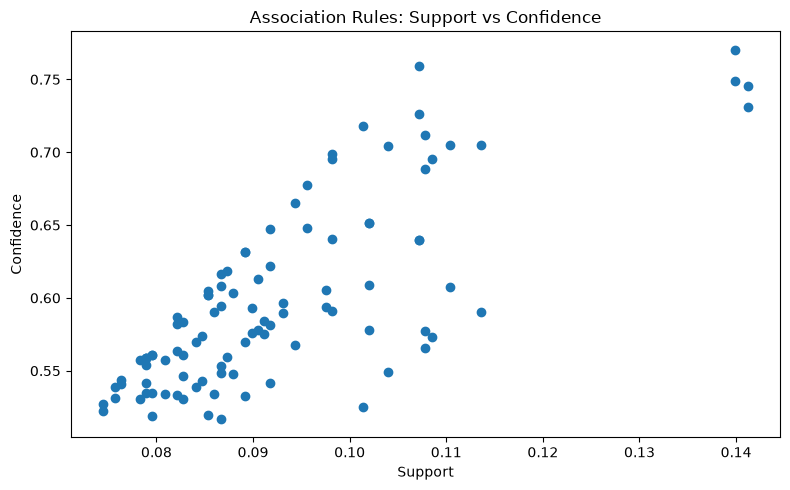

In [26]:
# Identify high-confidence but weak-lift rules
misleading = rules_df[
    (rules_df["confidence"] >= 0.30) &
    (rules_df["lift"] < 1.05)
].sort_values("confidence", ascending=False)

print("High-confidence, near-independent rules:")
display(misleading[[
    "antecedent_title", "consequent_title",
    "support", "confidence", "lift"
]].head(10))

# Rule visualization
plot_rules = rules_df[rules_df["support"] >= MIN_SUPPORT].head(100)

plt.figure(figsize=(8, 5))
plt.scatter(plot_rules["support"], plot_rules["confidence"])
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules: Support vs Confidence")
plt.tight_layout()
plt.show()

## Sequence Construction and Leakage Control

Each user's ratings are sorted chronologically. A sequence example is:

**Movie A -> Movie B -> Movie C**

The next-step target is the genre of the next rated movie. To avoid leakage, features are constructed only from the current event and earlier information, and the final train/test split is based on the timestamp of the target event. No future ratings are used to build the feature for a prediction.

In [ ]:
# Attach movie genres to ratings
genre_cols = ["Action", "Adventure", "Animation", "Children's", "Comedy",
              "Crime", "Documentary", "Drama", "Fantasy", "Film-Noir",
              "Horror", "Musical", "Mystery", "Romance", "Sci-Fi",
              "Thriller", "War", "Western"]

movie_meta = items[["movie_id"] + genre_cols].copy()
seq = data.merge(movie_meta, on="movie_id", how="left")
seq = seq.sort_values(["user_id", "event_time", "timestamp", "movie_id"]).reset_index(drop=True)

# Get the first listed genre for each movie
def primary_genre(row):
    for g in genre_cols:
        if row[g] == 1:
            return g
    return np.nan

seq["current_genre"] = seq.apply(primary_genre, axis=1)
seq["next_movie_id"] = seq.groupby("user_id")["movie_id"].shift(-1)
seq["next_genre"] = seq.groupby("user_id")["current_genre"].shift(-1)
seq["next_time"] = seq.groupby("user_id")["event_time"].shift(-1)

# Remove rows where either the current or next movie has no genre
pairs = seq.dropna(subset=["current_genre", "next_genre", "next_time"]).copy()

print("Next-step examples:", len(pairs))
print(
    pairs[
        ["user_id", "event_time", "movie_id", "current_genre", "next_genre"]
    ].head()
)

Next-step examples: 99039
   user_id                event_time  movie_id current_genre next_genre
0        1 1997-09-22 21:57:58+00:00       168        Comedy     Action
1        1 1997-09-22 21:57:58+00:00       172        Action      Drama
2        1 1997-09-22 21:58:38+00:00       165         Drama      Crime
3        1 1997-09-22 21:59:16+00:00       156         Crime      Drama
4        1 1997-09-22 22:01:17+00:00       166         Drama      Drama


In [ ]:
# Time-based split using the target event time
cutoff = pairs["next_time"].quantile(1 - TEST_FRACTION)
train = pairs[pairs["next_time"] < cutoff].copy()
test = pairs[pairs["next_time"] >= cutoff].copy()

print("Cutoff:", cutoff)
print("Train rows:", len(train))
print("Test rows:", len(test))

print(
    "Train target range:",
    train["next_time"].min(),
    "to",
    train["next_time"].max()
)

print(
    "Test target range:",
    test["next_time"].min(),
    "to",
    test["next_time"].max()
)

assert train["next_time"].max() < test["next_time"].min()

Cutoff: 1998-03-07 02:21:09+00:00
Train rows: 79230
Test rows: 19809
Train target range: 1997-09-20 03:05:27+00:00 to 1998-03-07 02:20:47+00:00
Test target range: 1998-03-07 02:21:09+00:00 to 1998-04-22 23:10:38+00:00


## Classification Pipeline

The baseline predicts the next primary genre using the current genre, current rating, and the user's historical mean rating calculated from the training period. One-hot encoding is appropriate for the categorical genre. StandardScaler is applied to the numeric features inside the Pipeline so the transformation is fit only on the training data.

In [38]:
# Compute user historical mean rating using training events only
user_mean_train = (
    train.groupby("user_id")["rating"]
         .mean()
         .rename("user_mean_rating")
)

for frame in [train, test]:
    frame["user_mean_rating"] = frame["user_id"].map(user_mean_train)
    frame["user_mean_rating"] = frame["user_mean_rating"].fillna(
        train["rating"].mean()
    )

feature_cols = ["current_genre", "rating", "user_mean_rating"]

X_train = train[feature_cols]
y_train = train["next_genre"]

X_test = test[feature_cols]
y_test = test["next_genre"]

categorical_features = ["current_genre"]
numeric_features = ["rating", "user_mean_rating"]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numeric_features)
])

model = Pipeline([
    ("preprocess", preprocess),
    ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=SEED,
            class_weight="balanced"
        )
    )
])

model.fit(X_train, y_train)
pred = model.predict(X_test)
prob = model.predict_proba(X_test)
test_labels = sorted(y_test.unique())

print(
    classification_report(
        y_test,
        pred,
        labels=test_labels,
        zero_division=0
    )
)

print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Balanced accuracy:", round(balanced_accuracy_score(y_test, pred), 4))

print("\nClasses in y_test:")
print(sorted(y_test.unique()))

print("\nClasses predicted by the model:")
print(sorted(np.unique(pred)))

print("\nPredicted classes not in y_test:")
print(sorted(set(pred) - set(y_test)))

              precision    recall  f1-score   support

      Action       0.34      0.34      0.34      4832
   Adventure       0.00      0.00      0.00       718
   Animation       0.14      0.14      0.14       596
  Children's       0.06      0.13      0.09       515
      Comedy       0.31      0.27      0.29      4458
       Crime       0.00      0.00      0.00       984
 Documentary       0.01      0.40      0.02       151
       Drama       0.00      0.00      0.00      5579
   Film-Noir       0.02      0.10      0.04       246
      Horror       0.11      0.12      0.11       572
     Musical       0.01      0.03      0.02       166
     Mystery       0.00      0.00      0.00       378
     Romance       0.00      0.00      0.00       109
      Sci-Fi       0.00      0.00      0.00       219
    Thriller       0.00      0.00      0.00       170
         War       0.00      0.00      0.00         4
     Western       0.00      0.00      0.00       112

    accuracy              

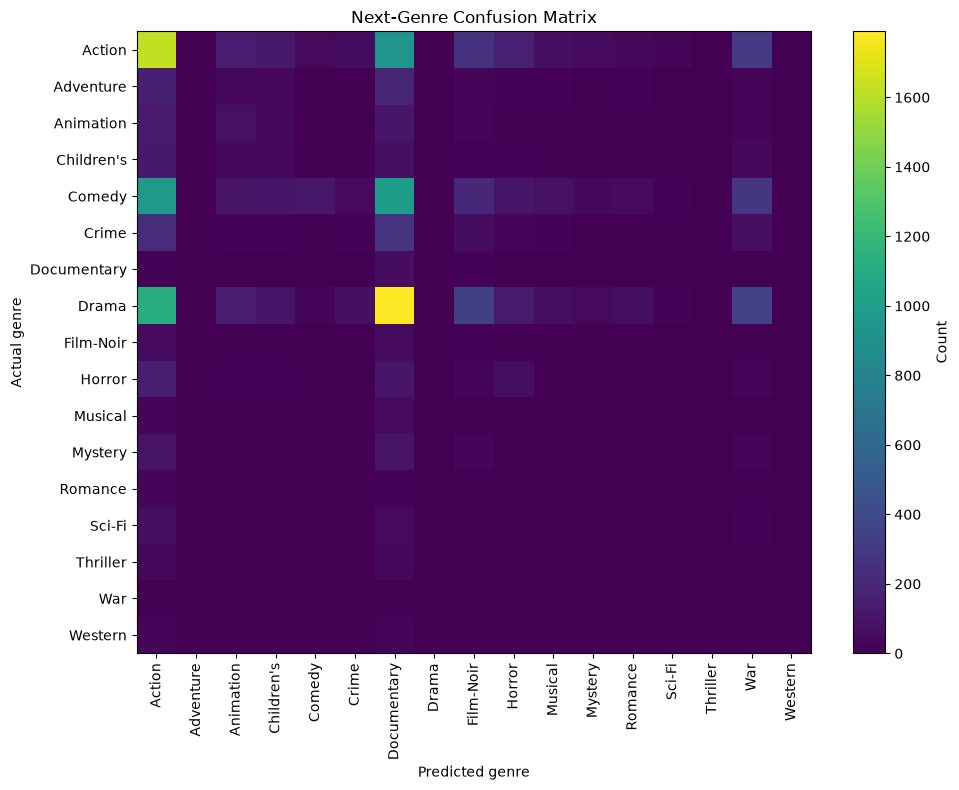

In [30]:
labels = sorted(y_test.unique())

cm = confusion_matrix(
    y_test,
    pred,
    labels=labels
)

plt.figure(figsize=(10, 8))
plt.imshow(cm, aspect="auto")
plt.xticks(range(len(labels)), labels, rotation=90)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted genre")
plt.ylabel("Actual genre")
plt.title("Next-Genre Confusion Matrix")
plt.colorbar(label="Count")
plt.tight_layout()
plt.show()

## Threshold and Decision Analysis

For a product system, the model does not have to make a recommendation for every case. A simple operating rule is to make a prediction only when the highest class probability reaches a chosen threshold. Otherwise, the system can defer to a popularity-based fallback or another ranking method. The comparison below uses two thresholds and reports both coverage and accuracy among accepted predictions.

In [31]:
max_prob = prob.max(axis=1)
pred_index = prob.argmax(axis=1)
class_names = model.named_steps["classifier"].classes_
pred_labels = class_names[pred_index]

decision_rows = []
for threshold in [0.40, 0.60]:
    accepted = max_prob >= threshold
    coverage = accepted.mean()
    accepted_accuracy = (
        accuracy_score(y_test.iloc[accepted], pred_labels[accepted])
        if accepted.any() else np.nan
    )
    decision_rows.append({
        "threshold": threshold,
        "coverage": coverage,
        "accepted_predictions": int(accepted.sum()),
        "accuracy_on_accepted": accepted_accuracy
    })

decision_df = pd.DataFrame(decision_rows)
display(decision_df)

,threshold,coverage,accepted_predictions,accuracy_on_accepted
0,0.4,0.000606,12,0.0
1,0.6,0.000202,4,0.0


### Decision interpretation
A lower threshold generally allows more predictions to be served, while a higher threshold is more selective. The appropriate operating point depends on the cost of an incorrect next-step prediction versus the cost of falling back to another recommendation method. These thresholds are operating examples, not universal values.

## 8. Reproducibility, monitoring, and inference constraints

**Artifacts:** archive checksum, dataset URL/version, notebook commit or version, Python/library versions, random seed, temporal cutoff, feature definitions, model parameters, and evaluation metrics.

**Monitoring:** monitor input missingness, genre-frequency drift, rating distribution drift, prediction confidence, fallback rate, next-genre accuracy/balanced accuracy when labels arrive, and rule support/lift decay.

**Association-rule monitoring:** alert when high-value rules fall below their minimum support or lift, or when firing rates change materially.

**Sequence monitoring:** track average sequence length, event intervals, transition frequencies, and the distribution of next-step labels.

**Inference cost:** a rule engine can be very fast when rules are indexed by antecedent, but rule sets can grow large. The classifier requires feature preprocessing and model scoring but has predictable per-request cost. Both approaches should be evaluated with latency, memory, and cache requirements in mind.

In [32]:
# Reproducibility record
run_metadata = {
    "seed": SEED,
    "dataset_url": DATA_URL,
    "archive_sha256": archive_sha256,
    "ratings_rows": len(data),
    "movie_rows": len(items),
    "association_transaction_definition": "user-week",
    "association_top_movies": TOP_MOVIES,
    "association_min_support": MIN_SUPPORT,
    "sequence_target": "next primary genre",
    "split": "time-based 80/20 using next event timestamp",
    "model": "LogisticRegression in sklearn Pipeline",
}
display(pd.Series(run_metadata))

seed                                                                                 42
dataset_url                           https://files.grouplens.org/datasets/movielens...
archive_sha256                        50d2a982c66986937beb9ffb3aa76efe955bf3d5c6b761...
ratings_rows                                                                     100000
movie_rows                                                                         1682
association_transaction_definition                                            user-week
association_top_movies                                                              100
association_min_support                                                            0.02
sequence_target                                                      next primary genre
split                                       time-based 80/20 using next event timestamp
model                                            LogisticRegression in sklearn Pipeline
dtype: object

## 9. Limitations and next steps

The association analysis was conducted on user-week baskets and only a few popular movies, so it is not representative of all possible definitions and the entire catalog. The sequence target narrows down multi-genre movies to one dominant genre, thus losing information. The baseline classifier has limited features, does not account for long history, and hence an improved follow-up experiment could include recent transitions, recency, movie embeddings, or a sequential model. Future experiments could also compare different time windows, analyze cold-start users separately, and evaluate the recommendations using offline ranking metrics or a controlled online experiment.